# S06: S05a residual signal with passive (limit-order) stock execution

Pre-registration: [`S06_README.md`](S06_README.md). Engine: `src/equity_trading/s06.py`.

Same signal as S05a. Stock legs are limit orders at the touch, filled only when the bar trades through by one quoted spread; exits fall back to market after 4 unfilled bars; ETF hedges are market orders. Costs and spreads are the S05b measurements.

The ETF hedge price inside the fill bar is unobservable on 15-minute bars, so it is bracketed: **mid** of the ETF bar (primary), **open** (optimistic), **next open** (conservative).

In [1]:
N_PLACEBO = 200           # gates are defined for 1000
N_JOBS = -1
PER_YEAR, WINDOW_S = 4, 3.0  # S05b quote samples (reused from the cache)

import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, s04, s05, s05b, s06
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("S06_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 not used
CFG = s06.S06Config(n_placebo=N_PLACEBO)
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 20

tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_s06{s06.S06_VERSION}_p{s04.PANEL_VERSION}"
OUT = ROOT / "results" / ("s06_synthetic" if SYNTHETIC else "s06")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "s06" / tag
CACHE.mkdir(parents=True, exist_ok=True)
PANEL_CACHE = s04.panel_cache_path(CFG.timeframe)   # shared across studies, keyed on PANEL_VERSION
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"{CFG.timeframe}_w{WINDOW_S:g}s"
QUOTE_CACHE.mkdir(parents=True, exist_ok=True)

COL = {"mid": "#2a78d6", "open": "#1baf7a", "next_open": "#eb6834", "grey": "#8a8a84"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})

if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
    BENCH = "XLK"
else:
    constituents = pd.read_csv(ROOT / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    BENCH = "SPY"
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | stocks={len(STOCKS)} | placebos={N_PLACEBO}")
print(CFG)

synthetic=False | stocks=503 | placebos=200
S06Config(timeframe='15Min', ffill_bars=2, window_sessions=20, min_bar_share=0.95, max_tau_frac=0.5, center_m=True, open_long=-1.25, open_short=1.25, close_long=-0.5, close_short=0.75, size_per_stock=0.01, max_positions=100, initial_equity=100000.0, fill_rule='through', exit_patience=4, hedge_timing='fill_bar_mid', capture_mult=1.0, cost_mult=1.0, n_placebo=200, seed=42)


## 1. Data: panel with raw high/low, measured costs

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, workers=8)
    panel = s04.cached_panel(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, ffill_bars=CFG.ffill_bars)   # shared, versioned panel cache
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
QUOTED = sorted(set(TRADED) | {ETF_OF[s] for s in TRADED})
print(f"panel {panel.c.shape} in {time.time() - t0:.0f}s | traded stocks {len(TRADED)}")

SESSIONS = s05b.sample_sessions(YEARS, PER_YEAR, seed=42)
if SYNTHETIC:
    samples = pd.DataFrame([(s, 3e-4, 10, k, d) for d in SESSIONS for k in range(26) for s in QUOTED],
                           columns=["symbol", "half_spread", "n_quotes", "slot", "date"])
else:
    missing = [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]
    print(f"quote sessions cached: {len(SESSIONS) - len(missing)}/{len(SESSIONS)}")
    for d in missing:
        sample_quote_spreads(QUOTED, d, s05b.slot_starts(YEARS, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
M = s05b.cost_model(samples)
H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, M)
print(f"measured half-spread: traded-stock bar median {np.median(H[:, SC]) * 1e4:.2f} bps, ETF {np.median(H[:, np.unique(EC)]) * 1e4:.2f} bps")

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
panel (39064, 513) in 10s | traded stocks 501
quote sessions cached: 24/24
measured half-spread: traded-stock bar median 3.01 bps, ETF 0.65 bps


## 2. Estimation (identical to S05a)

In [3]:
est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    t0 = time.time(); P = s05.estimate_all(panel, SC, EC, CFG.s05(), s06.first_decision_day(CFG))
    np.savez(est_path, **P); print(f"estimated in {time.time() - t0:.0f}s")

estimated in 47s


## 3. Backtests

| Run | Hedge price | Fill rule | Capture | Market costs | Role |
|---|---|---|---|---|---|
| primary | ETF bar mid | trade-through | 1× | 1× | gates G1–G3 |
| stress | ETF bar mid | trade-through | 0.5× | 2× | gate G4 |
| optimistic | ETF bar open | trade-through | 1× | 1× | bound, reported |
| conservative | next ETF open | trade-through | 1× | 1× | bound, reported (`EXECUTION_ROBUST`) |
| touch | ETF bar mid | touch | 1× | 1× | fill-rule sensitivity, reported |
| gross | ETF bar mid | trade-through | 1× | 0× | reported |

6 backtests in 134s; trading starts 2020-02-03


,total_return,sharpe,max_drawdown,mean_daily,days,entry_fill_rate,trades,passive_exit_share,capture,market_cost
primary,-0.4384,-1.6001,0.4383,-0.0004,1486.0,0.4634,56328.0,0.9458,32035.9022,9202.0255
stress,-0.5987,-2.6061,0.5964,-0.0006,1486.0,0.4026,56123.0,0.9481,13510.6222,15720.0920
optimistic,-0.2958,-0.9442,0.2990,-0.0002,1486.0,0.4819,56367.0,0.9452,36374.5480,10362.7094
conservative,-0.5271,-2.1160,0.5255,-0.0005,1486.0,0.4302,55613.0,0.9473,27098.2992,6333.1699
touch,0.2201,0.6015,0.1114,0.0001,1486.0,0.7505,57326.0,0.9937,57767.7462,12215.1589
gross,-0.3623,-1.2291,0.3635,-0.0003,1486.0,0.4746,56341.0,0.9454,34255.7043,0.0000


S05b reference (same signal, market orders, measured costs): total return -0.2532, Sharpe -0.752


,primary
trades,56328.0000
trades_per_day,37.8803
mean_signal_bps,-17.4159
capture_per_trade_bps,8.3447
market_cost_per_trade_bps,2.3970
median_bars,49.0000
passive_exit_share,0.9442
avg_open_positions,96.8403


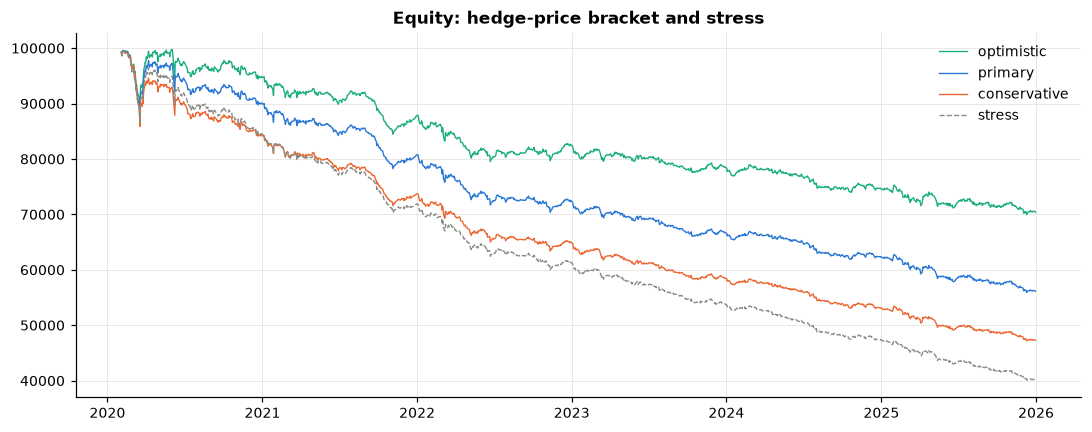

,2020,2021,2022,2023,2024,2025
primary net return by year,-0.1001,-0.1025,-0.1025,-0.0796,-0.0667,-0.0982


In [4]:
RUNS = {"primary": CFG, "stress": replace(CFG, capture_mult=0.5, cost_mult=2.0),
        "optimistic": replace(CFG, hedge_timing="fill_bar_open"), "conservative": replace(CFG, hedge_timing="next_open"),
        "touch": replace(CFG, fill_rule="touch"), "gross": replace(CFG, cost_mult=0.0)}
t0 = time.time()
res = {k: s06.backtest(panel, P, SC, EC, H, c, record=(k == "primary")) for k, c in RUNS.items()}
base = res["primary"]
START = base["first_day"]
print(f"{len(RUNS)} backtests in {time.time() - t0:.0f}s; trading starts {START.date()}")

rows = {}
for k, r in res.items():
    m = s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START)
    rows[k] = {**m, "entry_fill_rate": r["total_entry_fills"] / max(r["total_entry_orders"], 1),
               "trades": r["total_entry_fills"], "passive_exit_share": r["total_exit_passive"] / max(r["total_exit_passive"] + r["total_exit_market"], 1),
               "capture": r["total_capture"], "market_cost": r["total_cost"]}
metrics = pd.DataFrame(rows).T
display(metrics.round(4))
s05b_path = ROOT / "results" / "s05b" / "summary.json"
if s05b_path.exists() and not SYNTHETIC:
    ref = json.loads(s05b_path.read_text())["metrics"]["1x cost"]
    print(f"S05b reference (same signal, market orders, measured costs): total return {ref['total_return']:.4f}, Sharpe {ref['sharpe']:.3f}")

trades = base["trades"].copy()
trades["symbol"] = [TRADED[i] for i in trades["i"]]
tstats = {"trades": int(len(trades)), "trades_per_day": float(len(trades) / max(1, (pd.to_datetime(panel.days) >= START).sum())),
          "mean_signal_bps": float(1e4 * trades.signal_ret.mean()),
          "capture_per_trade_bps": float(1e4 * base["total_capture"] / trades.notional.sum()),
          "market_cost_per_trade_bps": float(1e4 * base["total_cost"] / trades.notional.sum()),
          "median_bars": float(trades.bars.median()), "passive_exit_share": float(trades.passive_exit.mean()),
          "avg_open_positions": float(base["n_open"][panel.day_start[s06.first_decision_day(CFG) + 1]:].mean())}
display(pd.Series(tstats).round(4).to_frame("primary"))
trades.drop(columns=["i"]).to_csv(OUT / "trades.csv", index=False, float_format="%.6g")
base["daily_equity"].to_csv(OUT / "daily_equity.csv", header=["equity"], float_format="%.2f")

fig, ax = plt.subplots(figsize=(10, 4))
for k, col in (("optimistic", COL["open"]), ("primary", COL["mid"]), ("conservative", COL["next_open"]), ("stress", COL["grey"])):
    e = res[k]["daily_equity"][res[k]["daily_equity"].index >= START]
    ax.plot(e.index, e, lw=0.9, color=col, label=k, ls="--" if k == "stress" else "-")
ax.set_title("Equity: hedge-price bracket and stress"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
e = base["daily_equity"][base["daily_equity"].index >= START]
eq_y = e.groupby(e.index.year).last()
display((eq_y / eq_y.shift(1).fillna(CFG.initial_equity) - 1).rename("primary net return by year").to_frame().T.round(4))

## 4. Placebos: random direction (signal P&L) and random contrarian timing (primary)

In [5]:
from joblib import Parallel, delayed
rand_dir = s05.random_direction_test(trades.signal_pnl.to_numpy(), n=10_000, seed=CFG.seed)
print("random direction:", {k: round(v, 4) for k, v in rand_dir.items()})
pl_path = CACHE / f"placebo_timing_{N_PLACEBO}.parquet"
if pl_path.exists():
    placebo = pd.read_parquet(pl_path)
else:
    t0 = time.time()
    placebo = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=2, verbose=5)(
        delayed(s06.run_placebo)(panel, P, SC, EC, H, CFG, base["entry_rate"], CFG.seed * 1000 + i, START) for i in range(N_PLACEBO)))
    placebo.to_parquet(pl_path); print(f"{N_PLACEBO} timing placebos in {(time.time() - t0) / 60:.1f} min")
placebo.to_csv(OUT / "placebo_timing.csv", index=False, float_format="%.6g")
bm = metrics.loc["primary"]
ranks = {k: s04.placebo_rank(bm[k], placebo[k].to_numpy()) for k in ("total_return", "sharpe")}
display(pd.DataFrame(ranks).T.round(4))

random direction: {'observed_gross': -66675.9622, 'p_upper': 1.0, 'percentile': 0.0, 'placebo_p95': 8465.397}


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  7.2min
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed: 25.6min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 31.5min finished


200 timing placebos in 31.5 min


,value,percentile,p_upper,placebo_median,placebo_p95
total_return,-0.4384,61.5,0.3881,-0.4416,-0.4192
sharpe,-1.6001,56.0,0.4428,-1.6117,-1.5027


## 5. Bootstrap, market exposure, gates

In [6]:
r_daily = base["daily_equity"][base["daily_equity"].index >= START].pct_change().dropna().to_numpy()
boot = {b: s04.block_bootstrap_mean(r_daily, b, 10_000, CFG.seed) for b in (10, 20, 40)}
display(pd.DataFrame(boot, index=["mean", "lo95", "hi95"]).T)
days = pd.to_datetime(panel.days)
bench_close = pd.Series(panel.c[panel.day_start[1:] - 1, panel.symbols.index(BENCH)], index=days)
mkt = s04.market_regression(base["daily_equity"][base["daily_equity"].index >= START], bench_close)
print("market regression vs", BENCH, {k: round(v, 5) for k, v in mkt.items()})
G = s05.gates(boot, rand_dir, ranks, metrics.loc["stress"].to_dict(), metrics.loc["primary"].to_dict())
G["G4_stress"] = G.pop("G4_double_cost")               # stress run: half capture, 2x market costs
G["EXECUTION_ROBUST"] = bool(metrics.loc["conservative", "total_return"] > 0 and metrics.loc["conservative", "sharpe"] > 0)
display(pd.Series(G).to_frame("S06"))
summary = {"study": "S06", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "trading_start": str(START.date()),
           "n_placebo": N_PLACEBO, "metrics": metrics.to_dict(orient="index"), "trade_stats": tstats, "random_direction": rand_dir,
           "placebo_timing_ranks": ranks, "bootstrap": {str(k): v for k, v in boot.items()}, "market": mkt, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "s06": s06.S06_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps({k: G[k] for k in ["statistical_verdict", "economic_verdict", "verdict", "EXECUTION_ROBUST"]}, indent=2))

,mean,lo95,hi95
10,-0.000376,-0.000562,-0.000189
20,-0.000376,-0.000554,-0.000197
40,-0.000376,-0.000492,-0.000215


market regression vs SPY {'alpha_daily': -0.00041, 'alpha_p': 0.0, 'beta': 0.0521, 'r2': 0.03367, 'n': 1486}


,S06
G1_bootstrap,False
G2_random_direction,False
G3_vs_random_timing,False
statistical_verdict,NO_SIGNAL
economic_verdict,NOT_PROFITABLE_AFTER_COSTS
verdict,NO_EDGE
G4_stress,False
EXECUTION_ROBUST,False


{
  "statistical_verdict": "NO_SIGNAL",
  "economic_verdict": "NOT_PROFITABLE_AFTER_COSTS",
  "verdict": "NO_EDGE",
  "EXECUTION_ROBUST": false
}
